# 14 · Agentic AI with LangGraph

Notebook 11 built the basic agent: a model that calls tools in a loop. Production agents need more structure around that loop, and **LangGraph** is the library most of the LangChain ecosystem uses for it (`create_agent` itself is a LangGraph graph). A LangGraph application is a **state machine**: a typed *state*, *nodes* that read the state and return updates, and *edges* (fixed or conditional) that decide which node runs next. On top of that it gives you persistence (checkpointers), pausing for a human (`interrupt`), long-term memory (stores) and streaming.

| pattern | problem it solves | LangGraph / LangChain tool |
|---|---|---|
| **graphs** | explicit, testable control flow | `StateGraph`, nodes, edges, conditional edges, reducers |
| **ReAct agent** | the model decides the next step | `langchain.agents.create_agent` |
| **guardrails** | agents loop, overspend, run forever | `recursion_limit`, `ModelCallLimitMiddleware`, `ToolCallLimitMiddleware`, custom middleware |
| **human in the loop** | risky actions need approval | `interrupt` + `Command(resume=...)`, `HumanInTheLoopMiddleware` |
| **memory** | continuity within and across conversations | checkpointer + `thread_id`, `InMemoryStore` with semantic search |
| **plan-and-execute** | long tasks get lost in one loop | an explicit planner / executor graph |
| **reflection** | first drafts are wrong; a checker can tell | generate / verify graph with a conditional edge |
| **multi-agent routing** | one prompt with every tool chooses badly | a router node and specialist subgraphs |

> **Workflow or agent?** A *workflow* follows code paths you wrote; an *agent* lets the model choose the next step. Agents are more flexible but slower, costlier and harder to test. Use the simplest design that works and add autonomy only where it measurably helps (Anthropic, *Building effective agents*, 2024). LangGraph is useful for both, which is why it is a good default.

Everything runs locally against `qwen2.5:3b` through Ollama. A 3B model is a weak agent, and we will see where it fails; the patterns and the evaluation method are what transfer to bigger models. With a LangSmith key in `.env`, every run below is traced to the project `llm-edu-suite-14-agentic`; open a trace to see each node, model call and tool call.

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-14-agentic")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : on (project: llm-edu-suite-14-agentic)


In [2]:
import os, operator
from typing import Annotated, Literal, TypedDict
from pydantic import BaseModel, Field
from langchain_core.tools import tool

ORDERS = {"A100": {"status": "shipped", "total": 120.0},        # a fake orders database
          "B200": {"status": "processing", "total": 45.5},
          "C300": {"status": "delivered", "total": 80.0}}
ISSUED_REFUNDS = []                                             # what the risky tool actually did, so we can check it

@tool
def order_status(order_id: str) -> dict:
    """Look up the status and the total (in dollars) of a customer order by its id, e.g. 'A100'."""
    return ORDERS.get(order_id.strip().upper(), {"error": f"order {order_id} not found"})

@tool
def calculate(expression: str) -> str:
    """Evaluate an arithmetic expression such as '120 * 1.21'. Use only digits, + - * / ( ) and dots."""
    if not all(ch in "0123456789+-*/(). " for ch in expression):
        raise ValueError(f"unsupported characters in {expression!r}; write plain arithmetic, e.g. 120 * 0.15 instead of 15% of 120")
    return str(round(eval(expression, {"__builtins__": {}}, {}), 4))

@tool
def issue_refund(order_id: str, amount: float) -> str:
    """Refund `amount` dollars to the customer for an order. This moves real money."""
    ISSUED_REFUNDS.append((order_id, amount))
    return f"Refunded {amount} dollars for order {order_id}."

RETRIEVER = None                                                # built on first use, so importing this cell needs no Ollama

def _retriever():
    global RETRIEVER
    if RETRIEVER is None:
        from langchain_core.documents import Document
        from langchain_core.vectorstores import InMemoryVectorStore
        folder = os.path.join(ROOT, "data", "sample_docs")
        docs = [Document(open(os.path.join(folder, f), encoding="utf-8").read(), metadata={"source": f}) for f in sorted(os.listdir(folder))]
        RETRIEVER = InMemoryVectorStore.from_documents(docs, get_embeddings()).as_retriever(search_kwargs={"k": 1})
    return RETRIEVER

@tool
def search_docs(query: str) -> str:
    """Search the company documentation: refunds, shipping times and costs, account security, support hours, API limits."""
    return "\n\n".join(d.page_content for d in _retriever().invoke(query))

READ_TOOLS = [order_status, calculate, search_docs]             # safe, read-only tools


import time
from collections import Counter
from langchain_core.messages import AIMessage
from langchain.agents.middleware import AgentMiddleware, ToolErrorMiddleware, hook_config
from langgraph.errors import GraphRecursionError

def tools_called(messages):
    """Names of the tools requested in a list of messages, in order."""
    return [tc["name"] for m in messages if isinstance(m, AIMessage) for tc in m.tool_calls]

def tool_precision_recall(called, expected):
    """Multiset precision and recall of the tools called against the expected ones (calling order_status twice for two orders counts twice)."""
    c, e = Counter(called), Counter(expected)
    hit = sum((c & e).values())
    precision = hit / sum(c.values()) if called else float(not expected)
    recall = hit / sum(e.values()) if expected else 1.0
    return precision, recall

def facts_ok(answer, facts):
    return all(f.lower() in str(answer).lower() for f in facts)

def stop_reason(result=None, error=None):
    """Why did the run end? Explicit stop reasons are what you alert on in production."""
    if isinstance(error, GraphRecursionError):
        return "recursion_limit"
    if error is not None:
        return f"error: {type(error).__name__}"
    last = result["messages"][-1]
    text = str(last.content)
    if text.startswith("Model call limits exceeded"):        # the message ModelCallLimitMiddleware(exit_behavior="end") writes
        return "model_call_limit"
    if text.startswith("Tool call limit reached"):           # the message ToolCallLimitMiddleware(exit_behavior="end") writes
        return "tool_call_limit"
    if text.startswith("Stopped: time limit"):               # the message our WallClockLimit writes
        return "timeout"
    if isinstance(last, AIMessage) and not last.tool_calls:
        return "answered"
    return "unknown"

class WallClockLimit(AgentMiddleware):
    """Stop the agent before the next model call once `seconds` have passed since the run started."""
    def __init__(self, seconds):
        super().__init__()
        self.seconds, self.t0 = seconds, None

    def before_agent(self, state, runtime):
        self.t0 = time.monotonic()                          # one run at a time; keep the start in state if runs are concurrent

    @hook_config(can_jump_to=["end"])
    def before_model(self, state, runtime):
        if time.monotonic() - self.t0 > self.seconds:
            return {"jump_to": "end", "messages": [AIMessage(f"Stopped: time limit of {self.seconds}s reached.")]}
        return None

def _tool_error(exc, request):
    """Bad input to a tool goes back to the model as a message so it can fix the call; other errors still stop the run."""
    if isinstance(exc, ValueError):
        return f"{request.tool_call['name']} failed: {exc}"
    return None

tool_errors_to_model = ToolErrorMiddleware(_tool_error)

llm = get_llm()
print("tools:", [t.name for t in READ_TOOLS + [issue_refund]])

tools: ['order_status', 'calculate', 'search_docs', 'issue_refund']


## 1. StateGraph fundamentals

Before adding a model, here is the machinery with plain Python functions: a ticket-triage graph.

- **State**: a `TypedDict`. Each node receives the whole state and returns a dict with *only the keys it changes*. By default an update replaces the old value; a **reducer** in `Annotated[type, reducer]` combines them instead (here `operator.add` appends to the log; `add_messages` does the same for chat messages and is what agents use).
- **Nodes**: functions `state -> update`.
- **Edges**: `add_edge(a, b)` always goes from a to b; `add_conditional_edges(a, fn)` calls `fn(state)` and goes to the node it names. `START` and `END` are the entry and exit.
- `compile()` checks the wiring and returns a runnable with `invoke`, `stream` and friends.

In [3]:
from langgraph.graph import StateGraph, START, END

class TriageState(TypedDict):
    ticket: str
    category: str
    reply: str
    log: Annotated[list[str], operator.add]     # a reducer: updates to `log` are appended instead of replacing it

def classify(state: TriageState) -> dict:
    text = state["ticket"].lower()
    category = ("billing" if any(w in text for w in ("refund", "charge", "invoice", "order")) else
                "urgent" if any(w in text for w in ("hacked", "breach", "stolen")) else "support")
    return {"category": category, "log": [f"classify -> {category}"]}          # a node returns only the keys it updates

def billing(state: TriageState) -> dict:
    return {"reply": "Forwarded to billing.", "log": ["billing"]}

def support(state: TriageState) -> dict:
    return {"reply": "Here is our help center link.", "log": ["support"]}

def urgent(state: TriageState) -> dict:
    return {"reply": "Paging the security on-call engineer.", "log": ["urgent"]}

def route_ticket(state: TriageState) -> Literal["billing", "support", "urgent"]:
    return state["category"]                    # the conditional edge: a function of the state that names the next node

builder = StateGraph(TriageState)
for name, fn in [("classify", classify), ("billing", billing), ("support", support), ("urgent", urgent)]:
    builder.add_node(name, fn)
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route_ticket)
for name in ("billing", "support", "urgent"):
    builder.add_edge(name, END)
triage = builder.compile()

for ticket in ["I want a refund for order A100", "How do I change my password?", "I think my account was hacked!"]:
    out = triage.invoke({"ticket": ticket})
    print(f"{ticket:35s} -> {out['category']:8s} {out['reply']:40s} log={out['log']}")

I want a refund for order A100      -> billing  Forwarded to billing.                    log=['classify -> billing', 'billing']
How do I change my password?        -> support  Here is our help center link.            log=['classify -> support', 'support']
I think my account was hacked!      -> urgent   Paging the security on-call engineer.    log=['classify -> urgent', 'urgent']


`stream(stream_mode="updates")` yields what each node returned, as it happens. With a model inside the nodes, this is how you show progress to a user (`stream_mode="messages"` streams the tokens).

In [4]:
for update in triage.stream({"ticket": "Please refund my last invoice"}, stream_mode="updates"):
    print(update)

{'classify': {'category': 'billing', 'log': ['classify -> billing']}}
{'billing': {'reply': 'Forwarded to billing.', 'log': ['billing']}}


Every compiled graph can be drawn. `draw_mermaid()` returns Mermaid text that renders on GitHub, in many editors and at mermaid.live; `draw_mermaid_png()` would render it to an image, but by default it calls the mermaid.ink web service, so we print the text to keep the notebook offline. Dotted arrows are conditional edges.

In [5]:
print(triage.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	classify(classify)
	billing(billing)
	support(support)
	urgent(urgent)
	__end__([<p>__end__</p>]):::last
	__start__ --> classify;
	classify -.-> billing;
	classify -.-> support;
	classify -.-> urgent;
	billing --> __end__;
	support --> __end__;
	urgent --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## 2. A ReAct agent with `create_agent`

**ReAct** (reason + act) is the loop from notebook 11: the model either calls tools or answers, and tool results go back to the model. `create_agent` builds it as a two-node graph (`model` and `tools`) with a conditional edge after the model. We give it the three read-only tools and the error middleware from the helpers cell (a `ValueError` in a tool becomes a message to the model instead of crashing the run).

In [6]:
from langchain.agents import create_agent

REACT_PROMPT = "You are a customer-service assistant. Use the tools to look up facts and to do arithmetic; never guess numbers. When you have everything, answer concisely."
react_agent = create_agent(llm, READ_TOOLS, system_prompt=REACT_PROMPT, middleware=[tool_errors_to_model])

t0 = time.time()
for update in react_agent.stream({"messages": [("user", "What is the status of order C300, and what is 10% of its total?")]}, stream_mode="updates"):
    for node, value in update.items():
        if not value:
            continue
        for m in value.get("messages", []):
            what = f"tool calls {[(tc['name'], tc['args']) for tc in m.tool_calls]}" if getattr(m, "tool_calls", None) else repr(str(m.content)[:120])
            print(f"[{node:5s}] {type(m).__name__:11s} {what}")
print(f"{time.time() - t0:.1f}s")

[model] AIMessage   tool calls [('order_status', {'order_id': 'C300'}), ('calculate', {'expression': 'total * 0.1'})]
[tools] ToolMessage '{"status": "delivered", "total": 80.0}'
[tools] ToolMessage "calculate failed: unsupported characters in 'total * 0.1'; write plain arithmetic, e.g. 120 * 0.15 instead of 15% of 120"


[model] AIMessage   tool calls [('calculate', {'expression': '80.0 * 0.1'}), ('order_status', {'order_id': 'C300'})]
[tools] ToolMessage '8.0'
[tools] ToolMessage '{"status": "delivered", "total": 80.0}'


[model] AIMessage   'The status of order C300 is delivered. 10% of its total is $8.0.'
4.2s


## 3. Guardrails: limits and explicit stop reasons

The most common production failure is not a wrong answer but an agent that **does not stop**: it repeats a call because it misreads the result, or keeps exploring and burns tokens. To see the guardrails work deterministically we use a deliberately broken "model", a fake chat model from `langchain_core` that requests the same tool call forever.

Four layers, from coarse to fine:
1. **`recursion_limit`** (a LangGraph run setting): the maximum number of graph steps (super-steps) in one run. Exceeding it raises `GraphRecursionError`. It is the last line of defence, and every run has one (default 25 in our version).
2. **`ModelCallLimitMiddleware`**: at most N model calls per run (`run_limit`) or per conversation thread (`thread_limit`). With `exit_behavior="end"` the agent stops gracefully with a message instead of raising.
3. **`ToolCallLimitMiddleware`**: the same for tool calls, globally or for one tool (`tool_name=...`).
4. **A wall-clock limit**: there is no built-in timeout middleware for synchronous runs, so we wrote `WallClockLimit` above. It is a small `AgentMiddleware` whose `before_model` hook returns `{"jump_to": "end"}` once the time is up. Custom middleware like this is how you add budgets in dollars, per-user quotas and similar policies.

Each run ends with a **stop reason** (`stop_reason` in the helpers cell); in production you count them and alert when `model_call_limit` or `timeout` spikes, which usually means a prompt or tool regression.

In [7]:
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain.agents.middleware import ModelCallLimitMiddleware, ToolCallLimitMiddleware

class ScriptedModel(GenericFakeChatModel):
    """Replays a fixed sequence of AIMessages; bind_tools is a no-op because the script already contains the tool calls."""
    def bind_tools(self, tools, **kwargs):
        return self

@tool
def slow_lookup(order_id: str) -> str:
    """A slow tool (0.5 s per call), to exercise the time limit."""
    time.sleep(0.5)
    return "status: shipped"

def stuck_model():
    """A broken model that ignores every result and asks for the same tool call again, forever."""
    return ScriptedModel(messages=iter([AIMessage("", tool_calls=[{"name": "slow_lookup", "args": {"order_id": "A100"}, "id": f"call_{i}"}]) for i in range(1000)]))

configs = {
    "recursion_limit=10 only": ([], {"recursion_limit": 10}),
    "ModelCallLimit(run_limit=4)": ([ModelCallLimitMiddleware(run_limit=4, exit_behavior="end")], {}),
    "ToolCallLimit(run_limit=3)": ([ToolCallLimitMiddleware(run_limit=3, exit_behavior="end")], {}),
    "WallClockLimit(1.2 s)": ([WallClockLimit(1.2)], {}),
}
for label, (middleware, config) in configs.items():
    agent = create_agent(stuck_model(), [slow_lookup], middleware=middleware)
    t0 = time.time(); result, error = None, None
    try:
        result = agent.invoke({"messages": [("user", "Where is order A100?")]}, config)
    except GraphRecursionError as e:
        error = e
    n_tools = len(tools_called(result["messages"])) if result else "n/a"
    last = str(result["messages"][-1].content)[:70] if result else str(error)[:70]
    print(f"{label:28s} stop={stop_reason(result, error):17s} tool calls={n_tools!s:4s} {time.time() - t0:4.1f}s  last: {last!r}")

recursion_limit=10 only      stop=recursion_limit   tool calls=n/a   2.5s  last: 'Recursion limit of 10 reached without hitting a stop condition. You ca'


ModelCallLimit(run_limit=4)  stop=model_call_limit  tool calls=4     2.0s  last: 'Model call limits exceeded: run limit (4/4)'


ToolCallLimit(run_limit=3)   stop=tool_call_limit   tool calls=4     1.5s  last: 'Tool call limit reached: run limit exceeded (4/3 calls).'


WallClockLimit(1.2 s)        stop=timeout           tool calls=3     1.5s  last: 'Stopped: time limit of 1.2s reached.'


Without middleware the loop only ended because the recursion limit raised an exception, after several tool calls and with nothing useful to show the user. With the middleware each run ends deliberately, with a message and a reason. (For `ToolCallLimit` the count includes the call that hit the limit: the model *requested* it, the middleware blocked it before it ran.) Typical production settings: 10 to 25 model calls, a per-request token or dollar budget, a timeout, plus a recursion limit as the backstop.

## 4. Human in the loop: an approval gate for a risky tool

Read-only tools can run freely; tools that **move money, send email or delete data** should wait for a person. LangGraph's primitive for this is `interrupt(value)`: the node pauses, the state is saved by the checkpointer, and the caller gets the `value` back. Later (seconds or days, from another process if the checkpointer is a database) someone calls `invoke(Command(resume=answer), config)` with the same `thread_id`, and `interrupt` returns `answer` inside the node.

First the primitive, in a three-node graph with no model involved:

In [8]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

class RefundState(TypedDict):
    order_id: str
    amount: float
    decision: dict
    result: str

def approval_gate(state: RefundState) -> dict:
    # interrupt() saves the state through the checkpointer and pauses the graph. The value is shown to the human;
    # the run continues when someone calls invoke(Command(resume=...)), and that resume value is returned here.
    decision = interrupt({"action": "issue_refund", "order_id": state["order_id"], "amount": state["amount"]})
    return {"decision": decision}

def after_review(state: RefundState) -> Literal["execute", "cancel"]:
    return "execute" if state["decision"].get("approved") else "cancel"

def execute_refund(state: RefundState) -> dict:
    return {"result": issue_refund.invoke({"order_id": state["order_id"], "amount": state["amount"]})}

def cancel_refund(state: RefundState) -> dict:
    return {"result": "Refund cancelled by reviewer: " + state["decision"].get("reason", "no reason given")}

gate = StateGraph(RefundState)
gate.add_node("approval_gate", approval_gate)
gate.add_node("execute", execute_refund)
gate.add_node("cancel", cancel_refund)
gate.add_edge(START, "approval_gate")
gate.add_conditional_edges("approval_gate", after_review)
gate.add_edge("execute", END)
gate.add_edge("cancel", END)
refund_flow = gate.compile(checkpointer=InMemorySaver())       # interrupts need a checkpointer to save the paused state

for thread, amount, decision in [("refund-1", 20.0, {"approved": True}),
                                 ("refund-2", 450.0, {"approved": False, "reason": "amounts above 100 dollars need a manager"})]:
    config = {"configurable": {"thread_id": thread}}
    paused = refund_flow.invoke({"order_id": "A100", "amount": amount}, config, version="v2")   # version="v2" returns a GraphOutput
    print(f"{thread}: paused at {refund_flow.get_state(config).next}, asking the human: {paused.interrupts[0].value}")
    done = refund_flow.invoke(Command(resume=decision), config, version="v2")
    print(f"          human said {decision} -> {done.value['result']}")
print("refunds actually issued:", ISSUED_REFUNDS)

refund-1: paused at ('approval_gate',), asking the human: {'action': 'issue_refund', 'order_id': 'A100', 'amount': 20.0}
          human said {'approved': True} -> Refunded 20.0 dollars for order A100.
refund-2: paused at ('approval_gate',), asking the human: {'action': 'issue_refund', 'order_id': 'A100', 'amount': 450.0}
          human said {'approved': False, 'reason': 'amounts above 100 dollars need a manager'} -> Refund cancelled by reviewer: amounts above 100 dollars need a manager
refunds actually issued: [('A100', 20.0)]


For agents built with `create_agent`, `HumanInTheLoopMiddleware` does this for you: it interrupts before any call to the tools you list, shows the proposed arguments, and accepts `approve`, `edit` (change the arguments), `reject` (with a message the model will read) or `respond`. Our "human" here is a policy function: approve refunds up to 40 dollars, reject the rest.

In [9]:
from langchain.agents.middleware import HumanInTheLoopMiddleware

hitl_agent = create_agent(
    llm, [order_status, issue_refund], system_prompt="You are a customer-service assistant. Use the tools to act on the user's request.",
    middleware=[HumanInTheLoopMiddleware(interrupt_on={"issue_refund": {"allowed_decisions": ["approve", "reject"]}})],
    checkpointer=InMemorySaver())

def reviewer(action):
    """Stands in for a person looking at the approval request."""
    if action["args"].get("amount", 0) <= 40:
        return {"type": "approve"}
    return {"type": "reject", "message": "Refunds above 40 dollars need a manager. Tell the customer a manager will contact them."}

ISSUED_REFUNDS.clear()
for thread, request in [("hitl-1", "Please refund 20 dollars for order A100, the item was scratched."),
                        ("hitl-2", "Refund the full 45.5 dollars of order B200 to me.")]:
    config = {"configurable": {"thread_id": thread}}
    out = hitl_agent.invoke({"messages": [("user", request)]}, config, version="v2")
    while out.interrupts:                                        # one interrupt per model turn that proposes gated calls
        actions = out.interrupts[0].value["action_requests"]
        decisions = [reviewer(a) for a in actions]
        print(f"{thread}: approval requested for {[(a['name'], a['args']) for a in actions]} -> {[d['type'] for d in decisions]}")
        out = hitl_agent.invoke(Command(resume={"decisions": decisions}), config, version="v2")
    print(f"{thread}: final answer: {out.value['messages'][-1].content[:200]!r}\n")
print("refunds actually issued:", ISSUED_REFUNDS)

hitl-1: approval requested for [('issue_refund', {'order_id': 'A100', 'amount': 20})] -> ['approve']


hitl-1: final answer: 'The refund for order A100 has been processed successfully. They have been refunded 20.0 dollars.'



hitl-2: approval requested for [('issue_refund', {'order_id': 'B200', 'amount': 45.5})] -> ['reject']


hitl-2: final answer: 'The refund process has been escalated to a manager due to the amount being above the threshold that allows for automatic processing. A manager will be in touch with you shortly to assist with this req'

refunds actually issued: [('A100', 20.0)]


The approval happens in your code, outside the model, so a prompt-injected or confused model cannot skip it. In a real system the interrupt payload goes to a review queue or a chat message, and the resume happens when a person clicks a button.

## 5. Memory

**Short-term memory** is the conversation itself. Compile an agent with a **checkpointer** and pass a `thread_id`: after every step the state (all messages) is saved under that thread, and the next `invoke` on the same thread starts from it. A different `thread_id` is a fresh conversation. `InMemorySaver` keeps it in RAM; `langgraph-checkpoint-postgres` or `-sqlite` persist it.

In [10]:
memory_agent = create_agent(llm, [order_status], system_prompt="You are a customer-service assistant.", checkpointer=InMemorySaver())
ana = {"configurable": {"thread_id": "ana-1"}}
memory_agent.invoke({"messages": [("user", "Hi, I'm Ana. My order number is B200.")]}, ana)
out = memory_agent.invoke({"messages": [("user", "What's the status of my order?")]}, ana)
print("same thread :", tools_called(out["messages"]), "->", out["messages"][-1].content[:150])
out = memory_agent.invoke({"messages": [("user", "What's the status of my order?")]}, {"configurable": {"thread_id": "someone-else"}})
print("new thread  :", tools_called(out["messages"]), "->", out["messages"][-1].content[:150])
print("messages saved in thread ana-1:", len(memory_agent.get_state(ana).values["messages"]))

same thread : ['order_status', 'order_status'] -> Your order with ID B200 is currently in the processing status. The total amount for your order is $45.50. Please check back soon for updates.


new thread  : [] -> Sure, I can help with that. Could you please provide me with your order ID?
messages saved in thread ana-1: 8


The thread grows with every turn, and every model call re-sends it, so cost and latency grow with the length of the conversation. For long threads add `SummarizationMiddleware` (it replaces old turns with a summary once a token threshold is reached) or trim messages.

**Long-term memory** is what should survive across threads: user preferences, facts, past decisions. LangGraph's **store** is a key-value store organised in namespaces (`("users", user_id)`), with optional **semantic search** when you give it an embedding model. Memory is retrieval, so we measure it like retrieval: recall@1 over a few questions.

In [11]:
from langgraph.store.memory import InMemoryStore

store = InMemoryStore(index={"embed": get_embeddings(), "dims": 768, "fields": ["text"]})   # nomic-embed-text has 768 dimensions
FACTS = ["Ana lives in Lima, Peru.",
         "Ana prefers short answers in Spanish.",
         "Ana's company sells handmade ceramics online.",
         "Ana's order A100 arrived late in March and she asked for a refund.",
         "Ana uses the public API from Python and hits the rate limit at peak hours."]
for i, fact in enumerate(FACTS):
    store.put(("users", "ana"), f"fact-{i}", {"text": fact})

MEMORY_EVAL = [("Which city is the customer in?", 0), ("What does her business sell?", 2), ("Has she had delivery problems?", 3),
               ("How should I format my replies?", 1), ("Which programming language does she use?", 4), ("Where does Ana live?", 0)]
hits = 0
for question, gold in MEMORY_EVAL:
    top = store.search(("users", "ana"), query=question, limit=1)[0]
    ok = top.value["text"] == FACTS[gold]; hits += ok
    print(f"{'OK  ' if ok else 'MISS'} {question:42s} -> ({top.score:.2f}) {top.value['text']}")
print(f"recall@1: {hits}/{len(MEMORY_EVAL)}")

OK   Which city is the customer in?             -> (0.54) Ana lives in Lima, Peru.
OK   What does her business sell?               -> (0.62) Ana's company sells handmade ceramics online.
OK   Has she had delivery problems?             -> (0.65) Ana's order A100 arrived late in March and she asked for a refund.
OK   How should I format my replies?            -> (0.54) Ana prefers short answers in Spanish.
MISS Which programming language does she use?   -> (0.53) Ana prefers short answers in Spanish.
OK   Where does Ana live?                       -> (0.86) Ana lives in Lima, Peru.
recall@1: 5/6


To use the store from an agent, tools and middleware get it through the **runtime**: a tool that declares a `runtime: ToolRuntime` parameter receives `runtime.store` and `runtime.context` (the model never sees that parameter). We give the agent a `save_memory` tool for writing, and for reading we do not rely on the model remembering to search: a `@dynamic_prompt` middleware retrieves the most relevant memories for the current user before every model call and puts them in the system prompt. The user id comes in through `context`, typed by `context_schema`.

In [12]:
import uuid
from langchain.tools import ToolRuntime
from langchain.agents.middleware import dynamic_prompt

warnings.filterwarnings("ignore", message="Pydantic serializer warnings")   # harmless noise when the run context is serialized for tracing

class UserContext(TypedDict):
    user_id: str

@tool
def save_memory(fact: str, runtime: ToolRuntime) -> str:
    """Save a lasting fact or preference about the user (e.g. where they live, how they like answers) for future conversations."""
    runtime.store.put(("users", runtime.context["user_id"]), str(uuid.uuid4()), {"text": fact})
    return "Saved."

@dynamic_prompt
def prompt_with_memories(request) -> str:
    user_id = request.runtime.context["user_id"]
    question = request.state["messages"][-1].content
    memories = request.runtime.store.search(("users", user_id), query=str(question), limit=3)
    known = "\n".join(f"- {m.value['text']}" for m in memories) or "- (nothing yet)"
    return ("You are a helpful assistant. When the user tells you a lasting fact or preference about themselves, call save_memory.\n"
            f"What you remember about this user:\n{known}")

long_memory_agent = create_agent(llm, [save_memory], middleware=[prompt_with_memories], store=store,
                                 context_schema=UserContext, checkpointer=InMemorySaver())
bob = {"user_id": "bob"}
out = long_memory_agent.invoke({"messages": [("user", "Please remember that I live in Toronto and I'm vegetarian.")]},
                               {"configurable": {"thread_id": "bob-monday"}}, context=bob)
print("thread 1 tool calls:", [(tc["name"], tc["args"]) for m in out["messages"] if isinstance(m, AIMessage) for tc in m.tool_calls])
print("store for bob:", [item.value["text"] for item in store.search(("users", "bob"))])
out = long_memory_agent.invoke({"messages": [("user", "Which city do I live in, and can you suggest a dinner for me?")]},
                               {"configurable": {"thread_id": "bob-friday"}}, context=bob)
print("thread 2 answer:", out["messages"][-1].content[:300])

thread 1 tool calls: [('save_memory', {'fact': "I live in Toronto and I'm vegetarian."})]
store for bob: ["I live in Toronto and I'm vegetarian."]


thread 2 answer: You live in Toronto. Since you are vegetarian, how about trying a dish like stuffed bell peppers or a vegetable stir-fry? Both are healthy and delicious options. Enjoy your dinner!


Two different threads, one store: the second conversation knows what the first one saved. Writing memory is the harder half in practice (what is worth keeping, deduplication, updates when facts change, privacy), which is why many systems run memory extraction as a separate background step instead of trusting the chat model to call a tool.

## 6. Plan-and-execute as an explicit graph

A request like *"look up order A100, add 21% tax, then find the refund policy"* needs several tools in sequence. A ReAct agent has to keep the whole task in mind while reading tool outputs. **Plan-and-execute** splits the work: a **planner** writes the list of steps (structured output, a Pydantic `Plan`), an **executor** runs one step at a time (a small ReAct agent limited to 3 model calls per step), and a **writer** composes the answer from the step results. The plan is inspectable and can be shown to a human before anything runs.

The graph: `plan`, then `execute` looping on itself through a conditional edge while steps remain, then `write_answer`.

In [13]:
class Plan(BaseModel):
    steps: list[str] = Field(description="The ordered steps. Each step is one plain-English instruction that needs exactly one tool.")

PLANNER_PROMPT = """You plan the work for a customer-service assistant. Split the user's request into the fewest steps, in order.
Each step is one plain-English instruction that needs exactly one of these tools:
- order_status: look up an order's status and total
- search_docs: look up company policies (refunds, shipping, security, support hours, API limits)
- calculate: arithmetic on numbers found in earlier steps
Do not add a step for writing the answer.
Example request: "What is order B200's total with a 10 dollar fee, and how long does express shipping take?"
Example steps: ["Look up the total of order B200", "Add 10 dollars to the total of order B200", "Search the docs for how long express shipping takes"]"""

STEP_PROMPT = ("You carry out ONE step of a plan with one tool call. Take numbers from the results of earlier steps. "
               "Reply with only the result of your step, in one short sentence; do not answer the rest of the request.")
WRITER_PROMPT = "Answer the user's request using only the step results below. Be concise and include every number that was asked for."

class PlanExecState(TypedDict):
    task: str
    plan: list[str]
    results: Annotated[list[str], operator.add]
    tools: Annotated[list[str], operator.add]
    model_calls: Annotated[int, operator.add]
    answer: str

def build_plan_execute(planner, step_agent, writer, max_steps=5):
    """planner: runnable returning a Plan; step_agent: an agent graph that runs one step; writer: chat model for the final answer."""
    def plan(state):
        p = planner.invoke([("system", PLANNER_PROMPT), ("user", state["task"])])
        return {"plan": p.steps[:max_steps], "model_calls": 1}

    def execute(state):
        i = len(state["results"])
        done = "\n".join(f"{n}. {s} -> {r}" for n, (s, r) in enumerate(zip(state["plan"], state["results"]), 1)) or "(none yet)"
        # The executor sees only its step and the earlier results, not the whole request, so it cannot try to do everything at once.
        out = step_agent.invoke({"messages": [("user", f"Results of earlier steps:\n{done}\n\nYour step: {state['plan'][i]}")]})
        msgs = out["messages"]
        return {"results": [str(msgs[-1].content)], "tools": tools_called(msgs),
                "model_calls": sum(isinstance(m, AIMessage) for m in msgs)}

    def next_step(state) -> Literal["execute", "write_answer"]:
        return "execute" if len(state["results"]) < len(state["plan"]) else "write_answer"

    def write_answer(state):
        lines = "\n".join(f"- {s}: {r}" for s, r in zip(state["plan"], state["results"]))
        a = writer.invoke([("system", WRITER_PROMPT), ("user", f"Request: {state['task']}\nStep results:\n{lines}")])
        return {"answer": a.content, "model_calls": 1}

    g = StateGraph(PlanExecState)
    g.add_node("plan", plan)
    g.add_node("execute", execute)
    g.add_node("write_answer", write_answer)
    g.add_edge(START, "plan")
    g.add_conditional_edges("plan", next_step)
    g.add_conditional_edges("execute", next_step)          # loop back to execute until every step has a result
    g.add_edge("write_answer", END)
    return g.compile()

step_agent = create_agent(llm, READ_TOOLS, system_prompt=STEP_PROMPT,
                          middleware=[ModelCallLimitMiddleware(run_limit=3, exit_behavior="end"), tool_errors_to_model])
plan_execute = build_plan_execute(planner=llm.with_structured_output(Plan), step_agent=step_agent, writer=llm)
print(plan_execute.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	plan(plan)
	execute(execute)
	write_answer(write_answer)
	__end__([<p>__end__</p>]):::last
	__start__ --> plan;
	execute -.-> write_answer;
	plan -.-> execute;
	plan -.-> write_answer;
	write_answer --> __end__;
	execute -.-> execute;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [14]:
t0 = time.time()
out = plan_execute.invoke({"task": "What is the status of order A100, and what is its total with 21% tax added?"})
for i, (step, result) in enumerate(zip(out["plan"], out["results"]), 1):
    print(f"step {i}: {step}\n        -> {result}")
print(f"\ntools: {out['tools']} | model calls: {out['model_calls']} | {time.time() - t0:.1f}s")
print("answer:", out["answer"])

step 1: Look up the status of order A100
        -> The order A100 is in a "shased" status with a total of $120.00.
step 2: Look up the total of order A100
        -> The total of order A100 is $120.00, as previously known.
step 3: Calculate 21% tax on the total of order A100
        -> The tax on the total of order A100 is $145.20.

tools: ['order_status', 'order_status', 'calculate'] | model calls: 8 | 3.5s
answer: The status of order A100 is "shased" with a total of $120.00. With 21% tax added, the total becomes $265.20.


Read the steps critically; this is what makes plan-and-execute easy to debug. With `qwen2.5:3b` the plans are often redundant (two steps that look up the same order), and a step result can contradict the tool output it was based on, for example by doing the arithmetic in its head instead of calling `calculate`. Every hand-off (plan to step, step to step, steps to writer) is a place where a small model can drop or distort information. Section 9 measures whether the structure pays for itself.

## 7. Reflection with a verifier

**Draft, verify, revise.** Reflection works when the verifier is *reliable*: unit tests for code, a schema validator, a SQL dry-run, a calculator. Asking the same model to critique itself without an external signal often does not help (Huang et al., 2024, *Large Language Models Cannot Self-Correct Reasoning Yet*).

The graph has a `generate` node (the model writes a function), a `verify` node (we run unit tests on it in a separate Python process with a timeout) and a conditional edge: stop if the tests pass or the round budget is spent, otherwise go back to `generate` with the failing test in the prompt.

In [15]:
import re, subprocess, sys, tempfile
from langchain_core.messages import HumanMessage, SystemMessage

def run_tests(code: str, tests: str, timeout: float = 10.0):
    """The verifier: run the candidate code and its unit tests in a separate Python process with a timeout."""
    with tempfile.TemporaryDirectory() as tmp:          # run from a file so the traceback shows the failing assert line
        path = os.path.join(tmp, "candidate.py")
        with open(path, "w", encoding="utf-8") as f:
            f.write(code + "\n\n" + tests + "\n")
        try:
            p = subprocess.run([sys.executable, "-I", path], capture_output=True, text=True, timeout=timeout, cwd=tmp)
        except subprocess.TimeoutExpired:
            return False, f"timed out after {timeout}s (infinite loop?)"
    if p.returncode == 0:
        return True, "all tests passed"
    lines = [l for l in p.stderr.strip().splitlines() if l.strip()]
    failing = next((l.strip() for l in reversed(lines) if l.strip().startswith("assert")), "")
    return False, (failing + "\n" if failing else "") + (lines[-1] if lines else "unknown error")

def extract_code(text: str) -> str:
    m = re.search(r"```(?:python)?\s*\n(.*?)```", text, re.S)
    return (m.group(1) if m else text).strip()

CODER_PROMPT = "You are an expert Python programmer. Reply with a single ```python code block containing only the function, no explanations and no tests."

class ReflectState(TypedDict):
    task: str
    tests: str
    code: str
    feedback: str
    passed: bool
    rounds: int
    history: Annotated[list[dict], operator.add]

def build_reflection(llm, verifier=run_tests, max_rounds=3):
    def generate(state):
        msgs = [SystemMessage(CODER_PROMPT), HumanMessage(state["task"])]
        if state.get("code"):                                # a revision: show the last attempt and what the verifier said
            msgs += [AIMessage(f"```python\n{state['code']}\n```"),
                     HumanMessage(f"The tests failed:\n{state['feedback']}\nFix the function and reply with the full corrected code.")]
        return {"code": extract_code(llm.invoke(msgs).content), "rounds": state.get("rounds", 0) + 1}

    def verify(state):
        passed, feedback = verifier(state["code"], state["tests"])
        return {"passed": passed, "feedback": feedback, "history": [{"round": state["rounds"], "passed": passed, "feedback": feedback}]}

    def should_retry(state) -> Literal["generate", "__end__"]:
        return END if state["passed"] or state["rounds"] >= max_rounds else "generate"

    g = StateGraph(ReflectState)
    g.add_node("generate", generate)
    g.add_node("verify", verify)
    g.add_edge(START, "generate")
    g.add_edge("generate", "verify")
    g.add_conditional_edges("verify", should_retry)
    return g.compile()

reflection = build_reflection(llm, max_rounds=3)
print(reflection.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	generate(generate)
	verify(verify)
	__end__([<p>__end__</p>]):::last
	__start__ --> generate;
	generate --> verify;
	verify -.-> __end__;
	verify -.-> generate;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [16]:
CODE_TASKS = [
    ("Write a Python function `days_in_month(year, month)` that returns the number of days in that month of the Gregorian calendar.",
     "assert days_in_month(2023, 4) == 30\nassert days_in_month(2024, 2) == 29\nassert days_in_month(1900, 2) == 28\nassert days_in_month(2000, 2) == 29"),
    ("Write a Python function `is_palindrome(s)` that returns True if `s` reads the same backwards, ignoring case, spaces and punctuation.",
     "assert is_palindrome('A man, a plan, a canal: Panama')\nassert not is_palindrome('hello')\nassert is_palindrome('')"),
    ("Write a Python function `roman_to_int(s)` that converts a Roman numeral string to an integer.",
     "assert roman_to_int('III') == 3\nassert roman_to_int('IV') == 4\nassert roman_to_int('MCMXCIV') == 1994"),
    ("Write a Python function `flatten(xs)` that flattens an arbitrarily nested list into a flat list.",
     "assert flatten([1, [2, [3, [4]], 5]]) == [1, 2, 3, 4, 5]\nassert flatten([]) == []\nassert flatten([[[]]]) == []"),
    ("Write a Python function `rle(s)` that run-length encodes a string, writing each character followed by its count, e.g. 'aaabcc' -> 'a3b1c2'.",
     "assert rle('aaabcc') == 'a3b1c2'\nassert rle('') == ''\nassert rle('abc') == 'a1b1c1'"),
    ("Write a Python function `second_largest(xs)` that returns the second largest distinct value in a list, or None if there is none.",
     "assert second_largest([3, 1, 3, 2]) == 2\nassert second_largest([5, 5]) is None\nassert second_largest([]) is None"),
    ("Write a Python function `merge_intervals(intervals)` that merges overlapping or touching intervals given as [start, end] lists and returns them sorted.",
     "assert merge_intervals([[1, 3], [2, 6], [8, 10]]) == [[1, 6], [8, 10]]\nassert merge_intervals([[1, 4], [4, 5]]) == [[1, 5]]\nassert merge_intervals([]) == []\nassert merge_intervals([[5, 6], [1, 2]]) == [[1, 2], [5, 6]]"),
    ("Write a Python function `top_words(text, k)` that returns the k most frequent lowercase words as (word, count) tuples, sorted by count descending and then alphabetically.",
     "assert top_words('b a b c a b', 2) == [('b', 3), ('a', 2)]\nassert top_words('y x', 2) == [('x', 1), ('y', 1)]\nassert top_words('A a', 1) == [('a', 2)]"),
]
reflection_rows = []
for task, tests in CODE_TASKS:
    t0 = time.time()
    out = reflection.invoke({"task": task, "tests": tests})
    first = out["history"][0]["passed"]
    reflection_rows.append({"first": first, "final": out["passed"], "rounds": out["rounds"], "sec": time.time() - t0})
    name = task.split("`")[1]
    print(f"{name:28s} round 1 {'pass' if first else 'FAIL'} | final {'pass' if out['passed'] else 'FAIL'} after {out['rounds']} round(s) "
          f"| {time.time() - t0:4.1f}s | last feedback: {out['history'][-1]['feedback'].splitlines()[0][:70]}")
n_code = len(reflection_rows)
print(f"\npass rate: {sum(r['first'] for r in reflection_rows)}/{n_code} on the first draft, "
      f"{sum(r['final'] for r in reflection_rows)}/{n_code} with up to 3 rounds of test feedback")

days_in_month(year, month)   round 1 pass | final pass after 1 round(s) |  1.8s | last feedback: all tests passed


is_palindrome(s)             round 1 FAIL | final FAIL after 3 round(s) |  6.4s | last feedback: assert is_palindrome('A man, a plan, a canal: Panama')


roman_to_int(s)              round 1 FAIL | final FAIL after 3 round(s) |  6.3s | last feedback: assert roman_to_int('IV') == 4


flatten(xs)                  round 1 pass | final pass after 1 round(s) |  0.6s | last feedback: all tests passed


rle(s)                       round 1 FAIL | final FAIL after 3 round(s) |  4.6s | last feedback: assert rle('aaabcc') == 'a3b1c2'


second_largest(xs)           round 1 pass | final pass after 1 round(s) |  0.6s | last feedback: all tests passed


merge_intervals(intervals)   round 1 pass | final pass after 1 round(s) |  1.7s | last feedback: all tests passed


top_words(text, k)           round 1 FAIL | final FAIL after 3 round(s) |  8.1s | last feedback: assert top_words('A a', 1) == [('a', 2)]

pass rate: 4/8 on the first draft, 4/8 with up to 3 rounds of test feedback


**Reading the result.** The tasks that pass on the first draft (half of them in this run) cost nothing extra: the conditional edge ends the run after one verification. Compare the two pass rates printed above to see what the feedback rounds added. With a 3B model the gain is modest and noisy: across our runs `top_words` (lower-casing plus the tie-breaking rule) never passed in three rounds, while `is_palindrome` was repaired by the feedback in one run and not in another. When the model does not know how to fix a bug, seeing the failing assert does not help. Reflection pays off when the model is close to right and the verifier says precisely what is wrong, which is why the verifier runs the code in a file: the traceback then contains the exact failing `assert` line, not just `AssertionError`. Cost grows with the rounds, so cap them and log the round count per request.

## 8. Multi-agent: a router and specialist subgraphs

Instead of one agent with every tool and a long prompt, a **router** sends each request to a **specialist** with a short prompt and only the tools it needs. Fewer tools per prompt means fewer wrong tool choices and fewer prompt tokens, at the cost of one extra model call for routing.

Here the router is a structured-output call (`Route` with a `Literal` destination), and its node returns a `Command(goto=...)`, which updates the state and chooses the next node in one return value. The specialists are `create_agent` agents added to the parent graph **as nodes**: a compiled graph used as a node is a *subgraph*, sharing the `messages` key with the parent. (The other common design, a supervisor agent that calls specialists wrapped as tools, uses the same building blocks.)

In [17]:
from langgraph.graph import MessagesState

class Route(BaseModel):
    destination: Literal["billing", "support", "general"] = Field(
        description="billing: orders, payments, refunds, totals and arithmetic on them; support: company policies such as shipping, "
                    "security, passwords, support hours, the API; general: greetings and anything else")

class RouterState(MessagesState):
    route: str

def build_router(classify, specialists: dict):
    """classify(messages) -> name of a specialist; specialists: name -> compiled graph (for example a create_agent agent)."""
    def router(state) -> Command:
        dest = classify(state["messages"])
        return Command(goto=dest, update={"route": dest})     # Command = state update + where to go next, in one return value

    g = StateGraph(RouterState)
    g.add_node("router", router, destinations=tuple(specialists))   # destinations only matter for drawing the graph
    for name, agent in specialists.items():
        g.add_node(name, agent)                                  # a compiled graph used as a node is a subgraph
        g.add_edge(name, END)
    g.add_edge(START, "router")
    return g.compile()

ROUTER_PROMPT = "You route customer messages to the right team. Pick the destination that should handle the latest message."
route_llm = llm.with_structured_output(Route)
classify = lambda messages: route_llm.invoke([("system", ROUTER_PROMPT)] + list(messages)).destination

specialists = {
    "billing": create_agent(llm, [order_status, calculate], name="billing", middleware=[tool_errors_to_model],
                            system_prompt="You handle orders and payments. Look up orders and do arithmetic with the tools."),
    "support": create_agent(llm, [search_docs], name="support",
                            system_prompt="You answer questions about company policies. Always search the docs first and answer from them."),
    "general": create_agent(llm, [], name="general", system_prompt="You are a friendly assistant for an online shop. Keep it short."),
}
router_app = build_router(classify, specialists)
print(router_app.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	router(router)
	billing(billing)
	support(support)
	general(general)
	__end__([<p>__end__</p>]):::last
	__start__ --> router;
	router -.-> billing;
	router -.-> general;
	router -.-> support;
	billing --> __end__;
	general --> __end__;
	support --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [18]:
ROUTING_EVAL = [("Where is my order B200?", "billing"), ("I was charged twice for order A100", "billing"),
                ("What is the total of order C300 with 21% tax?", "billing"), ("I need an invoice for my last order", "billing"),
                ("How long does express shipping take?", "support"), ("How do I enable two-factor authentication?", "support"),
                ("What are your support hours?", "support"), ("What is the API rate limit?", "support"),
                ("Do you ship to Canada?", "support"), ("Hello! How are you today?", "general"),
                ("Can you recommend a gift for my mother?", "general"), ("Thanks, that's all for today!", "general")]
labels = ["billing", "support", "general"]
confusion = np.zeros((3, 3), dtype=int)
t0 = time.time()
for text, gold in ROUTING_EVAL:
    pred = classify([("user", text)])
    confusion[labels.index(gold), labels.index(pred)] += 1
    if pred != gold:
        print(f"misrouted: {text!r} -> {pred} (expected {gold})")
routing_acc = np.trace(confusion) / len(ROUTING_EVAL)
print(f"routing accuracy {routing_acc:.0%} on {len(ROUTING_EVAL)} requests, {(time.time() - t0) / len(ROUTING_EVAL):.2f}s per routing call")

for request in ["What is the total of order A100 plus 15 dollars of express shipping?", "Within how many days can I get a full refund?"]:
    out = router_app.invoke({"messages": [("user", request)]})
    print(f"\n{request}\n  route={out['route']} tools={tools_called(out['messages'])}\n  answer: {out['messages'][-1].content[:200]}")

misrouted: 'Where is my order B200?' -> support (expected billing)


misrouted: 'Do you ship to Canada?' -> general (expected support)


misrouted: 'Hello! How are you today?' -> support (expected general)


misrouted: "Thanks, that's all for today!" -> support (expected general)
routing accuracy 67% on 12 requests, 0.23s per routing call



What is the total of order A100 plus 15 dollars of express shipping?
  route=billing tools=['order_status']
  answer: The total of order A100 is $120.00. Adding the $15 for express delivery, the total amount would be $135.00.



Within how many days can I get a full refund?
  route=support tools=['search_docs']
  answer: Based on the refund policy provided in the documentation, customers can get a full refund within 30 days of purchase. After 30 days, the refund is issued as store credit. For annual subscriptions, if 


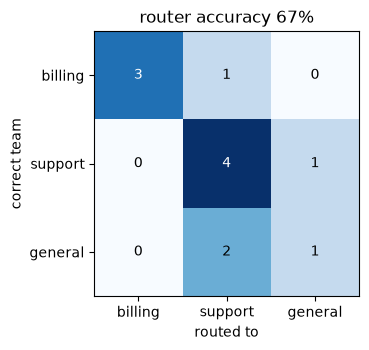

In [19]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(confusion, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, confusion[i, j], ha="center", va="center", color="white" if confusion[i, j] > confusion.max() / 2 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels(labels); ax.set_yticks(range(3)); ax.set_yticklabels(labels)
ax.set_xlabel("routed to"); ax.set_ylabel("correct team"); ax.set_title(f"router accuracy {routing_acc:.0%}")
plt.tight_layout(); plt.show()

**Reading the result.** The misroutes printed above are informative. Greetings and thank-yous went to `support` instead of `general`, a sign that "anything else" is too vague a description for a small model (an explicit list of examples per destination usually fixes this), and "Where is my order B200?" went to `support`, probably because "where is my order" sounds like a shipping question; it is ambiguous even for people. In production you would measure the router on a few hundred real messages, add a fallback for low-confidence routes, and log every routing decision so misroutes can be reviewed. The two end-to-end examples show the payoff: each specialist saw only its own tools.

## 9. Evaluation: single ReAct agent vs plan-and-execute

Ten multi-step requests, each labelled with the tools a correct solution needs and the facts the answer must contain. For each design we report:

- **success**: every expected fact appears in the final answer;
- **tool precision / recall**: multiset overlap between the tools called and the expected ones (precision drops with redundant or wrong calls, recall with missing ones);
- **model calls** (steps) and **latency** per task.

The ReAct agent gets a limit of 8 model calls per task; the plan-and-execute executor gets 3 per step.

In [20]:
EVAL_TASKS = [
    ("What is the status of order A100, and what is its total with 21% tax added?", ["order_status", "calculate"], ["shipped", "145.2"]),
    ("How much does express shipping cost, and how much would 3 express shipments cost in total?", ["search_docs", "calculate"], ["45"]),
    ("Has order B200 shipped yet? Also, within how many days can I get a full refund?", ["order_status", "search_docs"], ["processing", "30"]),
    ("What is the combined total of orders A100 and C300?", ["order_status", "order_status", "calculate"], ["200"]),
    ("What is the API rate limit per minute, and how many requests is that per hour?", ["search_docs", "calculate"], ["6000"]),
    ("Order C300: what is its status, and what is 10% of its total?", ["order_status", "calculate"], ["delivered", "8"]),
    ("What is the minimum password length, and what encryption is used for data at rest?", ["search_docs"], ["12", "AES-256"]),
    ("What is the total of order B200 split equally between 2 people?", ["order_status", "calculate"], ["22.75"]),
    ("Above what order amount is standard shipping free, and by how much does order A100's total exceed it?", ["search_docs", "order_status", "calculate"], ["50", "70"]),
    ("On which days is chat support available, and what is 15% of order A100's total?", ["search_docs", "order_status", "calculate"], ["Monday", "18"]),
]
react_eval = create_agent(llm, READ_TOOLS, system_prompt=REACT_PROMPT,
                          middleware=[ModelCallLimitMiddleware(run_limit=8, exit_behavior="end"), tool_errors_to_model])
eval_rows = []
for task, expected, facts in EVAL_TASKS:
    t0 = time.time()
    try:
        out = react_eval.invoke({"messages": [("user", task)]}, {"recursion_limit": 25})
        called, answer, calls = tools_called(out["messages"]), out["messages"][-1].content, sum(isinstance(m, AIMessage) for m in out["messages"])
        reason = stop_reason(out)
    except Exception as e:                     # a failed run is a failed task, not a crashed notebook
        called, answer, calls, reason = [], "", 0, stop_reason(error=e)
    p, r = tool_precision_recall(called, expected)
    eval_rows.append({"design": "ReAct", "task": task, "success": facts_ok(answer, facts), "precision": p, "recall": r,
                      "calls": calls, "sec": time.time() - t0, "stop": reason, "tools": called, "answer": answer})
    t0 = time.time()
    try:
        out = plan_execute.invoke({"task": task})
        called, answer, calls, reason = out["tools"], out["answer"], out["model_calls"], "answered"
    except Exception as e:
        called, answer, calls, reason = [], "", 0, stop_reason(error=e)
    p, r = tool_precision_recall(called, expected)
    eval_rows.append({"design": "plan-and-execute", "task": task, "success": facts_ok(answer, facts), "precision": p, "recall": r,
                      "calls": calls, "sec": time.time() - t0, "stop": reason, "tools": called, "answer": answer})
    a, b = eval_rows[-2], eval_rows[-1]
    print(f"{task[:62]:62s} ReAct {'OK ' if a['success'] else 'BAD'} {a['calls']:2d} calls {a['sec']:4.1f}s | "
          f"P&E {'OK ' if b['success'] else 'BAD'} {b['calls']:2d} calls {b['sec']:4.1f}s")

summary = {}
for design in ("ReAct", "plan-and-execute"):
    rs = [r for r in eval_rows if r["design"] == design]
    summary[design] = {k: float(np.mean([r[k] for r in rs])) for k in ("success", "precision", "recall", "calls", "sec")}
    summary[design]["stops"] = dict(Counter(r["stop"] for r in rs))
print()
for design, s in summary.items():
    print(f"{design:17s} success {s['success']:.0%} | tool precision {s['precision']:.0%} | tool recall {s['recall']:.0%} "
          f"| {s['calls']:.1f} model calls | {s['sec']:.1f}s per task | stop reasons {s['stops']}")

What is the status of order A100, and what is its total with 2 ReAct OK   3 calls  1.8s | P&E BAD  8 calls  3.3s


How much does express shipping cost, and how much would 3 expr ReAct OK   2 calls  1.7s | P&E OK   6 calls  2.4s


Has order B200 shipped yet? Also, within how many days can I g ReAct OK   2 calls  4.4s | P&E BAD  6 calls  3.6s


What is the combined total of orders A100 and C300?            ReAct OK   2 calls  1.8s | P&E OK   8 calls  3.2s


What is the API rate limit per minute, and how many requests i ReAct BAD  2 calls  3.3s | P&E BAD  6 calls  2.1s


Order C300: what is its status, and what is 10% of its total?  ReAct OK   2 calls  0.8s | P&E OK   6 calls  2.5s


What is the minimum password length, and what encryption is us ReAct OK   2 calls  0.8s | P&E OK   6 calls  2.2s


What is the total of order B200 split equally between 2 people ReAct OK   2 calls  1.0s | P&E OK   4 calls  1.3s


Above what order amount is standard shipping free, and by how  ReAct BAD  2 calls  1.4s | P&E OK   8 calls  6.2s


On which days is chat support available, and what is 15% of or ReAct OK   2 calls  1.4s | P&E BAD  8 calls  3.4s

ReAct             success 80% | tool precision 90% | tool recall 70% | 2.1 model calls | 1.8s per task | stop reasons {'answered': 10}
plan-and-execute  success 60% | tool precision 87% | tool recall 90% | 6.6 model calls | 3.0s per task | stop reasons {'answered': 10}


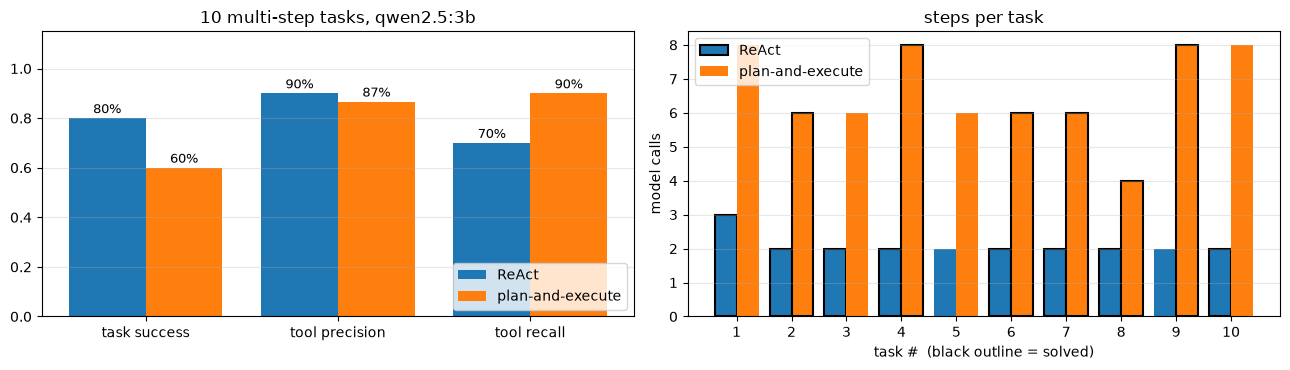

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
keys = ["success", "precision", "recall"]; xs = np.arange(len(keys))
for k, (design, color) in enumerate([("ReAct", "tab:blue"), ("plan-and-execute", "tab:orange")]):
    vals = [summary[design][key] for key in keys]
    ax[0].bar(xs + (k - 0.5) * 0.4, vals, 0.4, label=design, color=color)
    for x, v in zip(xs, vals): ax[0].text(x + (k - 0.5) * 0.4, v + 0.02, f"{v:.0%}", ha="center", fontsize=9)
ax[0].set_xticks(xs); ax[0].set_xticklabels(["task success", "tool precision", "tool recall"]); ax[0].set_ylim(0, 1.15)
ax[0].legend(loc="lower right"); ax[0].set_title(f"{len(EVAL_TASKS)} multi-step tasks, qwen2.5:3b")
idx = np.arange(len(EVAL_TASKS))
for k, (design, color) in enumerate([("ReAct", "tab:blue"), ("plan-and-execute", "tab:orange")]):
    rs = [r for r in eval_rows if r["design"] == design]
    ax[1].bar(idx + (k - 0.5) * 0.4, [r["calls"] for r in rs], 0.4, color=color, label=design,
              edgecolor=["black" if r["success"] else "none" for r in rs], linewidth=1.5)
ax[1].set_xticks(idx); ax[1].set_xticklabels([str(i + 1) for i in idx]); ax[1].set_xlabel("task #  (black outline = solved)")
ax[1].set_ylabel("model calls"); ax[1].set_title("steps per task"); ax[1].legend()
for a in ax: a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

In [22]:
for r in eval_rows:
    if not r["success"]:
        print(f"[{r['design']}] {r['task']}\n   tools {r['tools']} (stop: {r['stop']})\n   answer: {str(r['answer'])[:200]!r}\n")

[plan-and-execute] What is the status of order A100, and what is its total with 21% tax added?
   tools ['order_status', 'order_status', 'calculate'] (stop: answered)
   answer: 'The status of order A100 is "shased" with a total of $120.00. With a 21% tax added, the total becomes $265.20.'

[plan-and-execute] Has order B200 shipped yet? Also, within how many days can I get a full refund?
   tools ['order_status', 'search_docs'] (stop: answered)
   answer: 'Order B200 has not shipped yet. You can get a full refund within 30 days of purchase. Refunds are processed within 5 business days and returned to the original payment method.'

[ReAct] What is the API rate limit per minute, and how many requests is that per hour?
   tools ['search_docs'] (stop: answered)
   answer: 'The API is rate limited to 100 requests per minute. Therefore, per hour, that would be 600 requests (100 requests/minute * 60 minutes/hour).'

[plan-and-execute] What is the API rate limit per minute, and how many reques

**Reading the result honestly.** On these tasks the single ReAct agent did better than plan-and-execute, and it did so with about a third of the model calls. `qwen2.5:3b` often issues several tool calls in parallel in one turn, so most ReAct runs needed only two model calls. Plan-and-execute pays at least one planner call, one or more calls per step and one writer call, and every hand-off is a chance to lose information. The trade-off shows in the tool metrics: plan-and-execute had **higher tool recall** (the plan forces each sub-task to happen) but **lower precision** (redundant lookups when a step is phrased vaguely), while ReAct sometimes **skipped a tool it needed**. Its typical failures, listed above, were arithmetic done "in its head" instead of with `calculate` (wrong results) and a policy number invented instead of looked up with `search_docs`.

So with this model and these short tasks, planning did not pay off. That is not a general verdict: planning tends to help with longer tasks, with plans a human must approve, and with stronger planners. What transfers is the method: an eval set with expected trajectories and facts, the same metrics for every design, and a decision based on the numbers. With ten tasks one success is 10 points, so treat differences of one or two tasks as noise.

## Takeaways

- **LangGraph is a state machine:** typed state, nodes that return updates, reducers that merge them, fixed and conditional edges. Agents, planners, reflection loops and routers are all just graphs, which makes them inspectable, drawable and testable with fake models (see `tests/test_agents_langgraph.py`).
- **Every agent needs limits and a stop reason:** `recursion_limit` as the backstop, model and tool call limits that end gracefully, a time or cost budget, and a stop reason you can count.
- **Risky actions go through an approval gate** (`interrupt` / `HumanInTheLoopMiddleware`) that lives in your code, not in the prompt.
- **Memory = checkpointer (per thread) + store (across threads).** Long-term memory is retrieval: measure its recall, and decide carefully what gets written.
- **Structure helps most where verification is cheap:** reflection with real tests, routing evaluated as classification, plans you can inspect. Whether planning beats a single loop depends on the model and the task; measure it on your own eval set, as we did, instead of assuming.
- Other frameworks implement the same patterns (OpenAI Agents SDK, Claude Agent SDK, CrewAI, AutoGen); the concepts carry over. Notebook 15 adds observability and evaluation in LangSmith, and notebook 16 connects tools through the Model Context Protocol.

**Next:** `15_observability_llmops.ipynb`.